# 05 — What does a token cost Anthropic? Subscriptions vs the API

**Question:** a $200 Claude subscription can burn thousands of dollars of tokens at API list prices. Are subscriptions a loss leader paid for by fat API margins? And what does a token actually cost Anthropic to serve?

**Short answer**
1. Serving paying customers is cheap. In 9M-2026, cost of revenue (substantially all of it compute for customer-serving work) was **14.5 cents per dollar of revenue**, an ~85% gross margin, up from ~29% a year earlier. Only about a quarter of Anthropic's compute bill goes to serving paying customers. The rest is training, research, internal use of Claude and the free tier (§1, `05_cost_per_revenue_dollar.png`).
2. The S-1 doesn't split costs between subscriptions and the API, but it gives enough to bound the split. One unknown decides it: how many dollars of list-price tokens a subscriber burns per dollar of fee (the **usage multiple**). Outside measurements put it at **~6x on average** and **~34–60x for someone who maxes out their plan** (§2).
3. At ~6x, the S-1's totals imply roughly **93% gross margin on the API and ~57% on subscriptions**. That matches SemiAnalysis's independent estimate (>90% and 50–60%). **Subscriptions can't be below ~31% gross margin** whatever the multiple: even if every dollar of serving cost went to subscribers, the $4.8B wouldn't use up the $6.9B of subscription revenue (§2, `05_margin_vs_usage.png`).
4. The API's margin is less "insane" after distribution. Fees to cloud marketplaces (Bedrock, Vertex) were ~$4.8B or more in 9M-2026, about 18 points of consumption revenue. That takes the API from ~93% to ~75% before any R&D (§2).
5. In dollars, a token costs Anthropic roughly **7 cents per dollar of list price** (5–10 cents across plausible multiples). That's about **$1.40 per million output tokens on Opus 5.5** (list $20) and about **$0.01 per million cache reads**. A maxed-out Ultra plan costs ~$480 a month to serve against its $200 fee. The average subscriber costs ~$85 against $200. **Subscriptions are a gym membership, not a loss leader.** Light users pay for heavy ones (§3).
6. The real cost of a heavy subscriber is the API revenue the same compute could have earned. Anthropic says demand exceeds its compute. A maxed-out Ultra seat uses compute that could sell for ~$6,700 at list prices, for $200. That's the case for the weekly caps and the Max→Ultra repricing, not a loss on the books (§4).
7. Your assumption mostly holds, with one fix. Training is a big cost that volume has already overtaken: 9M-2026 gross profit ($28.4B) covered R&D ($19.2B). But training isn't fixed. R&D grew 5.4x year over year because each frontier model is replaced within months. It's a treadmill that grows with revenue, not a one-off cost spread over more tokens (§5).

| § | Question | Chart |
|---|---|---|
| 1 | What does it cost to serve $1 of revenue? | `05_cost_per_revenue_dollar.png` |
| 2 | How do subscription and API margins split? | `05_margin_vs_usage.png` |
| 3 | What is that per token, and per subscriber? | — |
| 4 | Are subscriptions a loss leader? | — |
| 5 | Is training a fixed cost that volume overtakes? | — |

**Inputs:** `income_statement`, `quarterly_income_statement`, `opex_by_function`, `revenue_breakdown`, `kpis` (S-1). Outside data (list prices, plan prices, measured subscription usage) is defined in one cell below and written to `data/external.csv` with `as_of`, `source_url` and `reliability`.
**Outputs:** `data/token_economics.csv` (implied cost and margins by usage multiple), `data/external.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import *

I = wide(load('income_statement'))
F = wide(load('opex_by_function'))
RB = load('revenue_breakdown')
RB = wide(RB[RB.dimension == 'pricing_model'])
Q = wide(load('quarterly_income_statement'))
K = load('kpis').set_index('metric')
kpi = lambda m: K.loc[m, 'value'] if np.ndim(K.loc[m, 'value']) == 0 else K.loc[m, 'value'].iloc[0]

### Outside data
None of this is in the S-1. Reliability flags:
- **primary:** Anthropic's own price list.
- **measured:** a third party metering real subscription accounts against usage limits.
- **analyst:** an estimate built partly on leaked financials.
- **press:** secondary reporting.

API prices come from Anthropic's pricing page (cached 2026-10-06). Cache writes cost 1.25x input and batch is 50% off; neither is used below.

In [2]:
EXT = [
    # item, value, unit, as_of, source_url, reliability, note
    ('opus_5_5_input', 4.00, 'usd_per_m_tokens', '2026-10-06', 'https://platform.claude.com/docs/en/about-claude/pricing', 'primary', ''),
    ('opus_5_5_output', 20.00, 'usd_per_m_tokens', '2026-10-06', 'https://platform.claude.com/docs/en/about-claude/pricing', 'primary', ''),
    ('opus_5_5_cache_read', 0.20, 'usd_per_m_tokens', '2026-10-06', 'https://platform.claude.com/docs/en/about-claude/pricing', 'primary', ''),
    ('fable_5_1_input', 10.00, 'usd_per_m_tokens', '2026-10-06', 'https://platform.claude.com/docs/en/about-claude/pricing', 'primary', ''),
    ('fable_5_1_output', 50.00, 'usd_per_m_tokens', '2026-10-06', 'https://platform.claude.com/docs/en/about-claude/pricing', 'primary', ''),
    ('fable_5_1_cache_read', 0.25, 'usd_per_m_tokens', '2026-10-06', 'https://platform.claude.com/docs/en/about-claude/pricing', 'primary', ''),
    ('sonnet_5_5_input', 2.00, 'usd_per_m_tokens', '2026-10-06', 'https://platform.claude.com/docs/en/about-claude/pricing', 'primary', ''),
    ('sonnet_5_5_output', 10.00, 'usd_per_m_tokens', '2026-10-06', 'https://platform.claude.com/docs/en/about-claude/pricing', 'primary', ''),
    ('sonnet_5_5_cache_read', 0.20, 'usd_per_m_tokens', '2026-10-06', 'https://platform.claude.com/docs/en/about-claude/pricing', 'primary', ''),
    ('haiku_5_5_input', 0.10, 'usd_per_m_tokens', '2026-10-06', 'https://platform.claude.com/docs/en/about-claude/pricing', 'primary', 'prompts up to 100K tokens'),
    ('haiku_5_5_output', 0.50, 'usd_per_m_tokens', '2026-10-06', 'https://platform.claude.com/docs/en/about-claude/pricing', 'primary', 'prompts up to 100K tokens'),
    ('plan_pro_fee', 20, 'usd_per_month', '2026-11-08', 'https://sessionwatcher.com/news/claude-ultra-200-month-max-100-pricing-page', 'press', 'Pro $20, Max $100, Ultra $200; Ultra is the renamed Max 20x (Oct 30, 2026)'),
    ('plan_max_fee', 100, 'usd_per_month', '2026-11-08', 'https://sessionwatcher.com/news/claude-ultra-200-month-max-100-pricing-page', 'press', ''),
    ('plan_ultra_fee', 200, 'usd_per_month', '2026-11-08', 'https://sessionwatcher.com/news/claude-ultra-200-month-max-100-pricing-page', 'press', ''),
    ('pro_full_use_api_value', 673, 'usd_per_month', '2026-11-02', 'https://wokey.ai/claude-usage-limits', 'measured', 'median $155/week ($146-173) at API list prices, ~92% cache reads; week of Oct 26-Nov 2 2026'),
    ('ultra_full_use_api_value', 6711, 'usd_per_month', '2026-11-02', 'https://wokey.ai/claude-usage-limits', 'measured', 'Max 20x (now Ultra): median $1,549/week ($1,216-1,697)'),
    ('ultra_full_use_api_value_semianalysis', 12000, 'usd_per_month', '2026-10-07', 'https://finance.biggo.com/news/173039423dab79be', 'analyst', 'SemiAnalysis (Kan, Megalaa): $200 plan ~ $12,000 of Opus 5.5 tokens at API rates'),
    ('avg_subscriber_utilization', 10, 'pct', '2026-10-07', 'https://finance.biggo.com/news/173039423dab79be', 'analyst', 'SemiAnalysis: ~10% average utilization, derived from leaked financials'),
    ('subscription_gm_semianalysis_low', 50, 'pct', '2026-10-07', 'https://finance.biggo.com/news/173039423dab79be', 'analyst', '$200 plan blended gross margin 50-60%'),
    ('subscription_gm_semianalysis_high', 60, 'pct', '2026-10-07', 'https://finance.biggo.com/news/173039423dab79be', 'analyst', ''),
    ('api_gm_semianalysis', 90, 'pct', '2026-10-07', 'https://finance.biggo.com/news/173039423dab79be', 'analyst', 'blended API gross margin "over 90%"'),
]
X = pd.DataFrame(EXT, columns=['item', 'value', 'unit', 'as_of', 'source_url', 'reliability', 'note'])
X.to_csv(DATA / 'external.csv', index=False)
x = X.set_index('item').value
X[['item', 'value', 'unit', 'reliability']]

,item,value,unit,reliability
0,opus_5_5_input,4.00,usd_per_m_tokens,primary
1,opus_5_5_output,20.00,usd_per_m_tokens,primary
2,opus_5_5_cache_read,0.20,usd_per_m_tokens,primary
3,fable_5_1_input,10.00,usd_per_m_tokens,primary
4,fable_5_1_output,50.00,usd_per_m_tokens,primary
5,fable_5_1_cache_read,0.25,usd_per_m_tokens,primary
6,sonnet_5_5_input,2.00,usd_per_m_tokens,primary
7,sonnet_5_5_output,10.00,usd_per_m_tokens,primary
8,sonnet_5_5_cache_read,0.20,usd_per_m_tokens,primary
9,haiku_5_5_input,0.10,usd_per_m_tokens,primary


## 1. What does it cost Anthropic to serve $1 of revenue?
**Why ask:** the S-1 never gives a cost per token. It does give **cost of revenue** in a note that sorts operating costs by function (Note 8). Per the filing, "substantially all" of it is "compute and infrastructure costs associated with customer-serving workloads". Revenue is tokens times price, so cost of revenue ÷ revenue is the cost of serving a dollar's worth of tokens. That's the number we want, expressed per dollar instead of per token.

**What sits elsewhere.** These costs are excluded from cost of revenue, per Note 8:
- **Research and development:** compute for model development, research and "internal usage" of Claude (90% of Anthropic's code is written by Claude), plus staff.
- **Sales and marketing:** channel-partner fees (the cut Bedrock and Vertex keep), advertising, and the compute for the **free tier**.

**Method:**
- Divide each functional cost line by revenue.
- Compare cost of revenue with the total compute bill (the natural-expense line in the income statement) to see how much compute serves paying customers.
- Leave out the one-off Bartz settlement, as in 02.

         revenue_$B  cost_of_revenue_$B  serving_cost_per_$  gross_margin  compute_$B  serving_share_of_compute
period                                                                                                         
FY2023        0.041               0.026               0.634         0.366       0.433                     0.060
FY2024        0.386               0.752               1.948        -0.948       2.522                     0.298
FY2025        4.585               2.773               0.605         0.395       7.326                     0.379
9M-2025       2.545               1.796               0.706         0.294       4.381                     0.410
9M-2026      33.242               4.812               0.145         0.855      18.808                     0.256


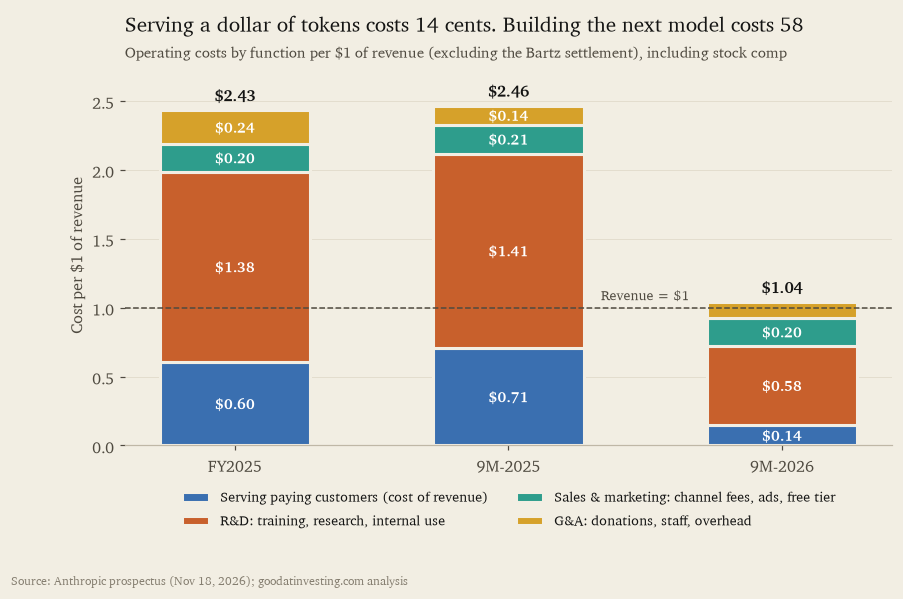

In [3]:
P = ['FY2023', 'FY2024', 'FY2025', '9M-2025', '9M-2026']
rev, cor, comp = I.loc['Revenue', P], F.loc['Cost of revenue', P], I.loc['Compute and infrastructure', P]
serve = pd.DataFrame({'revenue_$B': rev / 1000, 'cost_of_revenue_$B': cor / 1000,
                      'serving_cost_per_$': cor / rev, 'gross_margin': 1 - cor / rev,
                      'compute_$B': comp / 1000, 'serving_share_of_compute': cor / comp})
print(serve.round(3).to_string())

LINES = ['Cost of revenue', 'Research and development', 'Sales and marketing', 'General and administrative']
LABELS = ['Serving paying customers (cost of revenue)', 'R&D: training, research, internal use',
          'Sales & marketing: channel fees, ads, free tier', 'G&A: donations, staff, overhead']
PC = ['FY2025', '9M-2025', '9M-2026']
per_dollar = F.loc[LINES, PC] / I.loc['Revenue', PC]

fig, ax = plt.subplots(figsize=(9, 5.4))
xs, bottom = np.arange(len(PC)), np.zeros(len(PC))
for line, lab, col in zip(LINES, LABELS, SERIES):
    v = per_dollar.loc[line].values
    ax.bar(xs, v, 0.55, bottom=bottom, color=col, label=lab, edgecolor=SURFACE, linewidth=2)
    for xi, b, h in zip(xs, bottom, v):
        if h > 0.12:
            ax.text(xi, b + h / 2, f'${h:.2f}', ha='center', va='center', color='white', fontsize=9.5, fontweight='bold')
    bottom += v
for xi, t in zip(xs, bottom):
    ax.text(xi, t + 0.04, f'${t:.2f}', ha='center', va='bottom', color=INK, fontsize=10.5, fontweight='bold')
ax.axhline(1, color=INK2, lw=1, ls='--')
ax.text(1.5, 1.03, 'Revenue = $1', ha='center', va='bottom', color=INK2, fontsize=9)
ax.set_xticks(xs, PC)
ax.set_ylabel('Cost per $1 of revenue')
ax.set_ylim(0, bottom.max() * 1.12)
ax.set_title('Serving a dollar of tokens costs 14 cents. Building the next model costs 58')
subtitle(ax, 'Operating costs by function per $1 of revenue (excluding the Bartz settlement), including stock comp')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=9)
fig.subplots_adjust(bottom=0.24)
source(fig)
save(fig, '05_cost_per_revenue_dollar.png')
plt.show()

**What this shows** (`05_cost_per_revenue_dollar.png`):
- **Serving is the small part.** In 9M-2026 it cost **$0.145 per dollar of revenue**, an ~85.5% gross margin. A year earlier it was $0.71 (29% gross margin). It cost more than the revenue in FY2024.
- **Why it fell so fast.** The S-1 credits inference "compute multipliers" and price cuts that preserved margins. Revenue also grew 13x while cost of revenue grew 2.7x.
- **Most compute isn't serving paying customers.** Only ~26% of the 9M-2026 compute bill ($4.8B of $18.8B) is cost of revenue. The other ~74% trains and researches models, runs Claude inside Anthropic, and serves the free tier.
- **The "loss" lives in R&D,** not in token serving.
- **Caveat on the split.** Anthropic runs compute as "a single, shared resource across all workloads". So the split between serving and R&D is management's allocation, not separately metered hardware. The S-1 doesn't say how it's done.

**Next:** cost of revenue covers both subscriptions and the API. How does it split between them?

## 2. How do subscription and API margins split?
**Why ask:** this is the core of the question. API customers pay list price per token. Subscribers pay a flat fee and can burn many times that in list-price tokens.

**Method: one equation, two unknowns.** Treat every token as costing Anthropic the same fraction of its list price, called *c* (cost per $1 of list-price tokens). Then the S-1's 9M-2026 cost of revenue has to equal:

$$\text{CoR} = c \times \Big(\underbrace{\tfrac{R_{api}}{1-d}}_{\text{API tokens at list}} + \underbrace{m \times R_{sub}}_{\text{subscriber tokens at list}}\Big)$$

- $R_{api}$ = consumption revenue ($26.3B). $R_{sub}$ = subscription revenue ($6.9B). CoR = $4.8B. All three are from the S-1.
- *d* = the average discount API customers get off list (committed-spend contracts). Base case 0%; 20% as a test.
- *m* = the **usage multiple**: list-price dollars of tokens a subscriber burns per $1 of fee. This is the unknown that matters.

Given *m*, solve for *c*. Then:
- API gross margin = 1 − *c* ÷ (1 − *d*).
- Subscription gross margin = 1 − *c* × *m*.

**Evidence on *m*** (from `external.csv`):
- **Maxed-out plans:** metered at ~$673/month of list-price tokens on Pro ($20) and ~$6,711 on Max 20x/Ultra ($200), about **34x** (Wokey). SemiAnalysis measured ~$12,000 on the $200 plan, about **60x**.
- **The average subscriber** uses about 10% of the cap (SemiAnalysis, from leaked financials): 10% × $12,000 ÷ $200 ≈ **6x**. Our central case.

**A hard floor:** even if *c* × *m* soaked up the *entire* $4.8B, subscriptions would keep (6.9 − 4.8) ÷ 6.9 ≈ 31% gross margin. That needs no outside data.

In [4]:
R_api, R_sub = RB.loc['Consumption-based', '9M-2026'], RB.loc['Subscription-based', '9M-2026']
COR = F.loc['Cost of revenue', '9M-2026']
FEES = kpi('channel_partner_fee_increase')  # lower bound for 9M-2026 channel fees (S-1: "$4.8 billion increase")

def unit(m, d=0.0):
    """Implied serving cost per $1 of list-price tokens (c) and margins, for usage multiple m and API discount d."""
    c = COR / (R_api / (1 - d) + m * R_sub)
    return dict(m=m, d=d, c=c, api_gm=1 - c / (1 - d), api_after_channel_fees=1 - c / (1 - d) - FEES / R_api,
                sub_gm=1 - c * m)

FLOOR = 1 - COR / R_sub
assert abs(unit(1)['sub_gm'] - (1 - COR / (R_api + R_sub))) < 1e-12   # m=1: everyone has the blended margin
assert all(unit(m)['sub_gm'] > FLOOR for m in (1, 10, 1000))           # never below the floor

M_AVG = x['avg_subscriber_utilization'] / 100 * x['ultra_full_use_api_value_semianalysis'] / x['plan_ultra_fee']
M_FULL_LO = x['ultra_full_use_api_value'] / x['plan_ultra_fee']
M_FULL_HI = x['ultra_full_use_api_value_semianalysis'] / x['plan_ultra_fee']
print(f'usage multiple: average ~{M_AVG:.0f}x, maxed-out {M_FULL_LO:.0f}x-{M_FULL_HI:.0f}x; subscription floor {FLOOR:.1%}')
print(f'channel fees >= ${FEES/1000:.1f}B = {FEES/R_api:.1%} of consumption revenue')

GRID = [1, 2, 3, 4, 6, 8, 10, 15, 20, 34, 60]
TE = pd.DataFrame([unit(m, d) for d in (0.0, 0.2) for m in GRID])
TE['as_of'] = '9M-2026'
TE.to_csv(DATA / 'token_economics.csv', index=False)
print(TE[TE.m.isin([1, 3, 6, 10, 34, 60])].round(3).to_string(index=False))

usage multiple: average ~6x, maxed-out 34x-60x; subscription floor 30.6%
channel fees >= $4.8B = 18.2% of consumption revenue
 m   d     c  api_gm  api_after_channel_fees  sub_gm   as_of
 1 0.0 0.145   0.855                   0.673   0.855 9M-2026
 3 0.0 0.102   0.898                   0.715   0.694 9M-2026
 6 0.0 0.071   0.929                   0.747   0.575 9M-2026
10 0.0 0.050   0.950                   0.767   0.497 9M-2026
34 0.0 0.018   0.982                   0.799   0.376 9M-2026
60 0.0 0.011   0.989                   0.807   0.347 9M-2026
 1 0.2 0.121   0.849                   0.666   0.879 9M-2026
 3 0.2 0.090   0.888                   0.706   0.731 9M-2026
 6 0.2 0.065   0.919                   0.737   0.612 9M-2026
10 0.2 0.047   0.941                   0.759   0.529 9M-2026
34 0.2 0.018   0.978                   0.795   0.391 9M-2026
60 0.2 0.011   0.987                   0.804   0.357 9M-2026


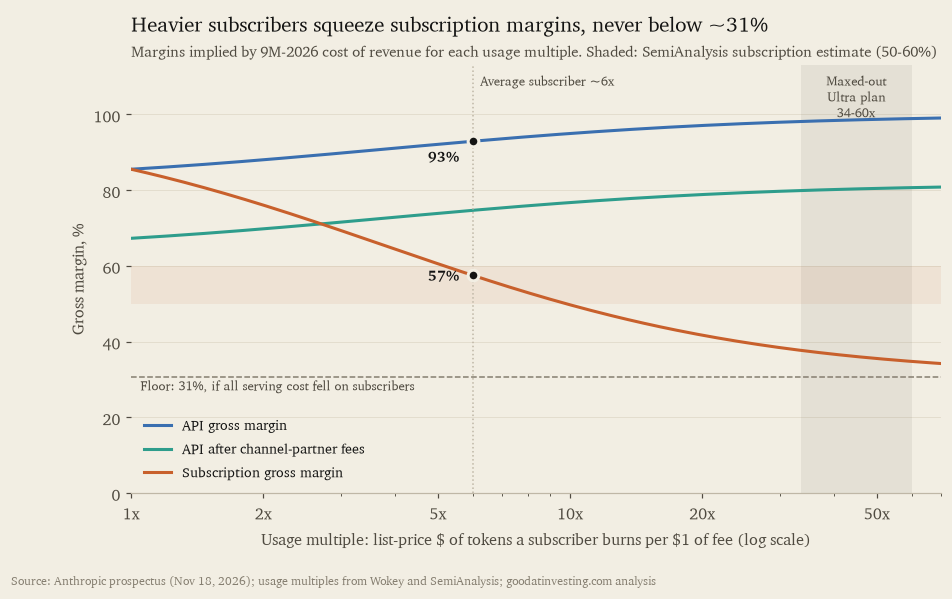

In [5]:
ms = np.geomspace(1, 70, 200)
u = pd.DataFrame([unit(m) for m in ms])
fig, ax = plt.subplots(figsize=(9.5, 5.4))
for col, c, lab in [('api_gm', SERIES[0], 'API gross margin'),
                    ('api_after_channel_fees', SERIES[2], 'API after channel-partner fees'),
                    ('sub_gm', SERIES[1], 'Subscription gross margin')]:
    ax.plot(u.m, u[col] * 100, color=c, label=lab)
ax.axhline(FLOOR * 100, color=NEUTRAL, ls='--', lw=1)
ax.text(1.05, FLOOR * 100 - 3.5, f'Floor: {FLOOR:.0%}, if all serving cost fell on subscribers', color=INK2, fontsize=8.5)
ax.axhspan(x['subscription_gm_semianalysis_low'], x['subscription_gm_semianalysis_high'], color=SERIES[1], alpha=0.08, lw=0)
ax.axvline(M_AVG, color=AXIS, lw=1, ls=':')
ax.text(M_AVG * 1.04, 111, f'Average subscriber ~{M_AVG:.0f}x', color=INK2, fontsize=8.5, va='top')
ax.axvspan(M_FULL_LO, M_FULL_HI, color=NEUTRAL, alpha=0.12, lw=0)
ax.text(np.sqrt(M_FULL_LO * M_FULL_HI), 111, f'Maxed-out\nUltra plan\n{M_FULL_LO:.0f}-{M_FULL_HI:.0f}x', color=INK2, fontsize=8.5, va='top', ha='center')
a = unit(M_AVG)
ax.plot([M_AVG] * 2, [a['api_gm'] * 100, a['sub_gm'] * 100], 'o', color=INK, ms=7, mec=SURFACE, mew=2, zorder=5)
ax.text(M_AVG * 0.93, a['sub_gm'] * 100, f"{a['sub_gm']:.0%}", ha='right', va='center', fontsize=9.5, fontweight='bold')
ax.text(M_AVG * 0.93, a['api_gm'] * 100 - 4, f"{a['api_gm']:.0%}", ha='right', va='center', fontsize=9.5, fontweight='bold')
ax.set_xscale('log')
ax.set_xticks([1, 2, 5, 10, 20, 50], ['1x', '2x', '5x', '10x', '20x', '50x'])
ax.set_xlim(1, 70)
ax.set_ylim(0, 113)
ax.legend(loc='lower left', fontsize=9)
fig.subplots_adjust(bottom=0.16)
ax.set_xlabel('Usage multiple: list-price $ of tokens a subscriber burns per $1 of fee (log scale)')
ax.set_ylabel('Gross margin, %')
ax.set_title('Heavier subscribers squeeze subscription margins, never below ~31%')
subtitle(ax, 'Margins implied by 9M-2026 cost of revenue for each usage multiple. Shaded: SemiAnalysis subscription estimate (50-60%)')
source(fig, 'Source: Anthropic prospectus (Nov 18, 2026); usage multiples from Wokey and SemiAnalysis; goodatinvesting.com analysis')
save(fig, '05_margin_vs_usage.png')
plt.show()

**What this shows** (`05_margin_vs_usage.png`):
- **At the average subscriber's ~6x,** the S-1's totals imply ~93% gross margin on the API and ~57% on subscriptions.
- **That matches SemiAnalysis.** Their independent estimate is >90% and 50–60%. Two separate methods meeting in the same place is the best evidence we have that ~6x is about right.
- **Heavier usage moves money between the two lines, not the total.** The more tokens subscribers burn, the cheaper each token must be (the total cost is fixed). So the API looks *better* and subscriptions worse. Even at 60x, subscriptions keep ~35%.
- **Channel fees take ~18 points off the API.** Bedrock, Vertex and the other cloud marketplaces book the revenue through Anthropic (gross), and Anthropic pays them a cut, recorded in sales and marketing. After that the API is ~75%, not ~93%. Subscriptions are sold mostly direct, which narrows the gap.
- **A 20% API discount** (in `token_economics.csv`) lowers the API margin only a point or two. It mainly makes *c* smaller per list dollar.

**Next:** what's *c* in dollars per token, and what does one subscriber cost?

## 3. What is that per token, and per subscriber?
**Method:**
- Take *c* at the central ~6x multiple, with a range from 3x to 10x.
- Multiply by Anthropic's list prices.
- This assumes every model carries the same markup. The S-1 doesn't say; Haiku probably earns less and Fable more.

For subscribers, we apply the same *c* to the measured list-price value of each plan:
- **Serving cost** = *c* × list-price tokens burned.
- **Gross profit** = fee − serving cost.

In [6]:
c_mid, c_hi, c_lo = unit(M_AVG)['c'], unit(3)['c'], unit(10)['c']
print(f'c = {c_mid:.3f} per $1 of list price (range {c_lo:.3f}-{c_hi:.3f})\n')
rows = []
for model in ['fable_5_1', 'opus_5_5', 'sonnet_5_5', 'haiku_5_5']:
    for kind in ['input', 'output', 'cache_read']:
        k = f'{model}_{kind}'
        if k in x:
            rows.append(dict(model=model, token=kind, list_per_M=x[k], cost_per_M=x[k] * c_mid,
                             cost_low=x[k] * c_lo, cost_high=x[k] * c_hi))
print(pd.DataFrame(rows).round(3).to_string(index=False))

subs = pd.DataFrame([
    ('Pro, maxed out (Wokey)', x['plan_pro_fee'], x['pro_full_use_api_value']),
    ('Ultra, maxed out (Wokey)', x['plan_ultra_fee'], x['ultra_full_use_api_value']),
    ('Ultra, maxed out (SemiAnalysis)', x['plan_ultra_fee'], x['ultra_full_use_api_value_semianalysis']),
    ('Ultra, average user (~6x)', x['plan_ultra_fee'], x['plan_ultra_fee'] * M_AVG),
    ('Pro, average user (~6x)', x['plan_pro_fee'], x['plan_pro_fee'] * M_AVG),
], columns=['subscriber', 'fee', 'list_value'])
subs['serving_cost'] = subs.list_value * c_mid
subs['gross_profit'] = subs.fee - subs.serving_cost
subs['api_revenue_forgone'] = subs.list_value - subs.fee
print('\n$ per month'); print(subs.round(0).to_string(index=False))

c = 0.071 per $1 of list price (range 0.050-0.102)

     model      token  list_per_M  cost_per_M  cost_low  cost_high
 fable_5_1      input       10.00       0.708     0.503      1.021
 fable_5_1     output       50.00       3.542     2.515      5.107
 fable_5_1 cache_read        0.25       0.018     0.013      0.026
  opus_5_5      input        4.00       0.283     0.201      0.409
  opus_5_5     output       20.00       1.417     1.006      2.043
  opus_5_5 cache_read        0.20       0.014     0.010      0.020
sonnet_5_5      input        2.00       0.142     0.101      0.204
sonnet_5_5     output       10.00       0.708     0.503      1.021
sonnet_5_5 cache_read        0.20       0.014     0.010      0.020
 haiku_5_5      input        0.10       0.007     0.005      0.010
 haiku_5_5     output        0.50       0.035     0.025      0.051

$ per month
                     subscriber   fee  list_value  serving_cost  gross_profit  api_revenue_forgone
         Pro, maxed out (Wokey) 

**What this shows:**
- **Serving costs ~7 cents per dollar of list price** (5–10 cents across 3x–10x). On Opus 5.5 that's about $0.28 per million input tokens, $1.40 per million output and ~$0.01 per million cache reads (list $4 / $20 / $0.20). Agentic use is >90% cache reads, which is why a subscriber can burn billions of tokens for a few hundred dollars of cost.
- **A maxed-out subscriber loses money:**
  - Ultra at Wokey's measured cap costs ~$480 a month to serve against a $200 fee. At SemiAnalysis's cap it's ~$850.
  - A maxed-out Pro user costs ~$48 against $20.
- **The average subscriber makes it back:** ~$85 of cost against $200.
- **So subscriptions are a gym membership.** Most members don't come every day, and they pay for the ones who do.
- **These are serving costs only,** before the R&D that builds the models, the free tier and overhead.

**Next:** gross profit is positive. Does that mean subscriptions aren't a loss leader?

## 4. Are subscriptions a loss leader?
**Two different lenses give two different answers.**

**On the books: no.**
- Subscriptions earn ~57% gross margin at the central case, and can't go below ~31%.
- Heavy users lose money, but light users more than make up for it.
- Subscription revenue grew from 17% of revenue in FY2025 to 21% in 9M-2026, and it's still margin-positive.

**In opportunity cost: yes, for heavy users.**
- The S-1 says Anthropic has "consistently operated in a compute-constrained environment where customer demand exceeds available compute". It also bought $5.0B of short-term compute in Q3-2026 at "significantly more" than contract rates.
- When compute is the bottleneck, a token served to a subscriber is a token not sold to an API customer.
- A maxed-out Ultra seat uses compute that could earn **~$6,500 a month more** at list prices than its $200 fee (the `api_revenue_forgone` column).
- On the margin, the real cost of a heavy subscriber is the API revenue it displaces, not the 7 cents.

**Why Anthropic does it anyway,** in its own words:
- Prosumers are "a powerful top-of-funnel engine": developers who use Claude Code at home take it to work.
- When subscribers hit their cap they "may utilize a higher subscription tier or purchase more intelligence directly". That's the bridge into consumption revenue.
- Inside Claude Enterprise, users who don't use Claude Code spend under $75 a month, while the top 5% who do spend ~20x that.

**How Anthropic manages it.** The caps do the work:
- Weekly limits.
- Max 20x renamed Ultra and given 10x Pro weekly usage instead of 20x.
- Overage at API rates.

**What to watch.** The S-1's own risk factor: agentic workloads "consume significantly more compute per user interaction", and flat-fee plans are where the heaviest agentic users live. If the average multiple drifts from ~6x toward ~20x, subscription margin falls from ~57% to ~42% (§2).

## 5. Is training a fixed cost that volume overtakes?
**Your assumption:** building a model is a big upfront cost, and only at enough volume does operating profit overtake it.

**Test:**
- Compare gross profit (revenue − serving cost) with R&D, the line that holds training compute.
- Check how compute scales with revenue quarter by quarter. The quarterly data has only the natural expense lines, not the functional split.

In [7]:
gp = I.loc['Revenue', P] - F.loc['Cost of revenue', P]
rd = F.loc['Research and development', P]
print(pd.DataFrame({'gross_profit_$B': gp / 1000, 'R&D_$B': rd / 1000, 'R&D_per_$_revenue': rd / I.loc['Revenue', P],
                    'gross_profit_covers_R&D': gp > rd}).round(2).to_string())
print(f"\nYoY 9M-2026 vs 9M-2025: revenue x{I.loc['Revenue','9M-2026']/I.loc['Revenue','9M-2025']:.1f}, "
      f"R&D x{rd['9M-2026']/rd['9M-2025']:.1f}, cost of revenue x{cor['9M-2026']/cor['9M-2025']:.1f}")

qp = [c for c in Q.columns if c.startswith('Q')]
q = pd.DataFrame({'revenue_$B': Q.loc['Revenue', qp] / 1000, 'compute_$B': Q.loc['Compute and infrastructure', qp] / 1000})
q['compute_per_$_revenue'] = q['compute_$B'] / q['revenue_$B']
print('\n', q.round(2).to_string())

         gross_profit_$B  R&D_$B  R&D_per_$_revenue  gross_profit_covers_R&D
period                                                                      
FY2023              0.02    0.42              10.29                    False
FY2024             -0.37    2.28               5.89                    False
FY2025              1.81    6.34               1.38                    False
9M-2025             0.75    3.59               1.41                    False
9M-2026            28.43   19.24               0.58                     True

YoY 9M-2026 vs 9M-2025: revenue x13.1, R&D x5.4, cost of revenue x2.7

          revenue_$B  compute_$B  compute_per_$_revenue
period                                                
Q1-2025        0.38        0.94                   2.51
Q2-2025        0.79        1.39                   1.77
Q3-2025        1.38        2.05                   1.48
Q4-2025        2.04        2.94                   1.44
Q1-2026        4.73        3.39                   0.72
Q2-

**What this shows:**
- **Volume has already overtaken the model-building bill.**
  - 9M-2026 gross profit of $28.4B covered R&D of $19.2B.
  - R&D fell from ~$10 per dollar of revenue (FY2023) to ~$0.58.
  - Total compute fell from $2.51 per revenue dollar (Q1-2025) to $0.48 (Q2-2026).
- **But training isn't fixed.** R&D grew **5.4x** in a year, slower than revenue (13x) but far from flat.
  - Each frontier model is replaced within months: Fable 5 → 5.1 and Opus 5 → 5.5 in 2026 alone.
  - Each new model comes with a 25–40% cut in cost per task for customers.
  - So the right picture is a **treadmill**: a training budget that grows with the business, paid for by the latest model's gross profit before the next one replaces it. It's not a fixed cost spread over ever more tokens.
- **What actually decides profitability** is the ratio of R&D to revenue, and 03's compute commitments. Today's gross margin on serving is not the question.
- **Compute is bought ahead of demand.** Q3-2026 compute rose back to $0.58 per revenue dollar: committed capacity arrived along with $5.0B of pricey short-term compute.
- **Two consequences:**
  - Margins swing with how revenue keeps up with contracted capacity (see 03).
  - The marginal token is cheap only while there's spare capacity.

## Findings, by section
1. **§1:** serving paying customers costs ~14.5 cents per revenue dollar (85.5% gross margin, 9M-2026). Only ~26% of compute does that; ~74% goes to training, research, internal use and the free tier.
2. **§2:** at the average subscriber's ~6x usage multiple, the API runs ~93% gross margin (~75% after channel fees) and subscriptions ~57%. Subscriptions can't fall below ~31%. These match SemiAnalysis's independent estimates.
3. **§3:**
   - Serving costs ~7 cents per list-price dollar: ~$1.40 per million Opus 5.5 output tokens.
   - Maxed-out subscribers are gross-loss-making (~$480 to serve a $200 Ultra plan); average ones are not (~$85).
4. **§4:** subscriptions are not a loss leader on the books. In a compute-constrained world, heavy subscribers cost the API revenue they displace (~$6,500 a month for a maxed-out Ultra seat), which is why the caps exist.
5. **§5:** volume has already overtaken model-building costs, but training is a growing treadmill, not a fixed cost.

## Caveats
- **Allocation.** Cost of revenue is management's allocation of a shared compute pool; the method isn't disclosed. A different split would move every number here.
- **Equal markup.** The method assumes every token costs the same fraction of its list price, across models and across subscription vs API. In reality, subscription traffic may lean to cheaper cached tokens, or to pricier models.
- **Usage multiples are outside estimates.**
  - The ~6x average rests on SemiAnalysis's ~10% utilization, from leaked financials.
  - The maxed-out figures are third-party metering over a single week.
  - "Subscription-based" revenue also includes Team and Enterprise seats, which may be used differently from Pro/Max/Ultra.
- **Channel fees.** $4.8B is the S-1's year-over-year *increase*, a lower bound; the true figure is $4.8–5.1B. Some subscriptions sold via app stores also pay a cut.
- **Policy-violator revenue.** 02 strips ~6% of 2026 revenue as policy-violator revenue. That revenue also used serving compute, so it's kept here. Removing it would lower margins slightly.

## Open items
- If a later amendment or 10-Q splits cost of revenue by pricing model, or gives token volumes, replace the equation in §2 with the disclosed numbers.
- Re-measure the usage multiples after the Ultra repricing (Oct 30, 2026).